# 05 · scuffedQuant: rotation, codebook, sketch, wire format and accuracy

The rotation lemma checked numerically, bit-packed wire size against FP8 and KIVI, the sketch's 1/sqrt(m) error law, round trip, and top-8 attention overlap per layer (mean ± std).

**README sections covered:** [11. scuffedQuant: rotate, quantize, sketch the residual](../docs/explained/11-scuffedquant.md)

Figures are written to `docs/figures/` (model figures: arithmetic, proofs and repo results) and `docs/figures/<MODE>/` (measured on the machine that ran the notebook).

In [1]:
MODE = "local"            # "local" | "cluster"
RESULTS_SUBDIR = "scuffedquant"
MODEL = "ibm-granite/granite-3.3-2b-instruct"
DEVICE = "cuda"            # cluster: cuda on server 1 / server 2
BITS = 3
QJL_DIM = 256
TOPK = 8
SEED = 0

In [2]:
import os, sys, json, socket, subprocess, time
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "middleware").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
HOST = socket.gethostname()
STAMP = time.strftime("%Y%m%dT%H%M%SZ", time.gmtime())
RESULTS = (ROOT / "benchmarks" / "results" / RESULTS_SUBDIR) if MODE == "cluster" else Path("/tmp/scuffed-local") / RESULTS_SUBDIR
RESULTS.mkdir(parents=True, exist_ok=True)
FIGDIR = ROOT / "docs" / "figures"
(FIGDIR / MODE).mkdir(parents=True, exist_ok=True)

import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "legend.fontsize": 7.5, "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.4,
    "lines.markersize": 4, "figure.constrained_layout.use": False})
C = {"hot": "#f97316", "cold": "#38bdf8", "spill": "#a78bfa", "ok": "#34d399", "bad": "#f43f5e",
     "gold": "#facc15", "ink": "#1f2937", "muted": "#94a3b8"}

def fig(name, model=False, caption=None, f=None):
    """Save the current figure as PNG + PDF and show it.
    model=True: arithmetic or repo results, same on every machine -> docs/figures/<name>
    model=False: measured on this machine -> docs/figures/<MODE>/<name>"""
    f = f or plt.gcf()
    d = FIGDIR if model else FIGDIR / MODE
    f.tight_layout()
    for ext in ("png", "pdf"):
        f.savefig(d / f"{name}.{ext}", bbox_inches="tight")
    print(f"figure -> {d.relative_to(ROOT)}/{name}.png" + (f"  |  {caption}" if caption else ""))
    plt.show()

def save(name, obj):
    p = RESULTS / f"{HOST}_{name}.json"
    obj = {"host": HOST, "utc": STAMP, "mode": MODE, **obj}
    p.write_text(json.dumps(obj, indent=2, default=str))
    print("wrote", p)
    return p

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True, cwd=ROOT)
    print(r.stdout[-4000:], r.stderr[-2000:])
    if check and r.returncode:
        raise RuntimeError(f"{cmd} -> {r.returncode}")
    return r
print("repo:", ROOT, "| host:", HOST, "| mode:", MODE, "| results ->", RESULTS, "| figures ->", FIGDIR)

repo: /home/claude/scuffedrdma | host: vm | mode: local | results -> /tmp/scuffed-local/scuffedquant | figures -> /home/claude/scuffedrdma/docs/figures


## Math: rotate, quantize, sketch the residual

scuffedQuant compresses one K or V vector $x \in \mathbb R^d$ in three steps ([docs/explained/11](../docs/explained/11-scuffedquant.md)):

1. **Normalize.** Store $\lVert x\rVert$ (4 bytes) and work with $\bar x = x / \lVert x \rVert$.
2. **Rotate.** $y = \tfrac{1}{\sqrt d} H D \bar x$ with $H$ the Walsh–Hadamard matrix and $D$ a fixed random $\pm1$ diagonal. *Lemma 2.1:* $\tfrac{1}{\sqrt d}HD$ is orthogonal, so norms and inner products are preserved. *Lemma 2.2:* every coordinate $y_i$ has mean 0 and variance $1/d$ whatever $\bar x$ was (the signs $D$ are the randomness), so an outlier channel in $x$ becomes $d$ small, alike coordinates in $y$. One fixed codebook then fits every coordinate of every vector; no per-group scales.
3. **Quantize** each $y_i$ to $b = 3$ bits with a Lloyd–Max codebook $\{c_1, \dots, c_8\}$ for $\mathcal N(0, 1/d)$: the two optimality conditions are that each boundary is the midpoint of its two levels and each level is the conditional mean of its cell. Reconstruction $\hat x$ is the un-rotated, rescaled codeword.
4. **Sketch the residual** $r = x - \hat x$ with $m = 256$ random $\pm1$ projections: keep $\lVert r \rVert$ (4 bytes) and $\mathrm{sign}(Sr)$ (256 bits). For a query $q$ the inner product is estimated as

$$
\langle q, k\rangle \;\approx\; \langle q, \hat k\rangle \;+\; \lVert r\rVert\,\frac{\sqrt{\pi/2}}{m}\sum_{j=1}^{m}\mathrm{sign}(Sr)_j\,(Sq)_j ,
$$

which is unbiased for Gaussian $S$ (Lemma 4.1: $\mathbb E[\mathrm{sign}(X)\,Y] = \sqrt{2/\pi}\,\sigma_{XY}/\sigma_X$ for jointly Gaussian $X, Y$) and approximately unbiased for the $\pm1$ projections the code uses; its standard error falls like $1/\sqrt m$ (Proposition 4.3). The figure below checks both the $1/\sqrt m$ law and the gain over the reconstruction alone.

**Wire format.** $4 + 4 + \lceil 3d/8\rceil + 32$ bytes per vector: **64 B at $d = 64$** (2× vs bf16, 4× vs fp32), 88 B at $d = 128$. Dropping the sketch gives $4 + 3d/8$: 28 B at $d = 64$.

**How it differs from FP8, KIVI and token eviction.** Those change the GPU cache that attention reads at every decode step (FP8: 1 byte per number plus a scale; KIVI: 2 bits with per-group scale and zero, keys per channel, values per token, newest tokens in full precision; eviction: drop tokens). scuffedQuant only changes bytes that leave the GPU, on the wire or on NVMe, and the receiver rebuilds bf16. Same bytes as FP8 at $d = 64$, 0.69× at $d = 128$; quality against FP8 and KIVI on the same KV is not measured yet. On the vLLM connector path the receiver calls `decompress()`, so the sketch is carried but unused there (section 6 of the write-up); the error figure below shows what that costs.

**What this notebook measures.** Packed sizes from real `pack()` output; the pack/unpack round trip; top-8 attention overlap per layer (synthetic KV in local mode, the real Granite 3.3-2B KV in cluster mode); and the Update 4 result file re-summarized as mean ± std.

In [3]:
import numpy as np
from middleware.rdma_tensor_cache.scuffed_quant import ScuffedQuant, CompressedKV

### 1. The rotation spreads outliers, and the codebook is fixed (model figure)

per-coordinate variance: raw unit vectors min/max 0.0049 0.233 | rotated min/max 0.0145 0.0169 | 1/d = 0.0156


figure -> docs/figures/11_rotation.png  |  Lemma 2.2: every rotated coordinate has variance 1/d


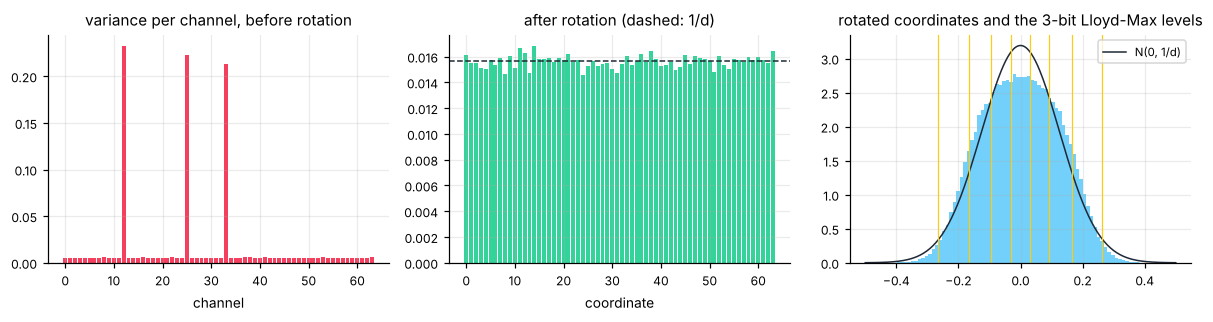

In [4]:
rng = np.random.default_rng(SEED)
d = 64
X = rng.standard_normal((2048, d)).astype(np.float32)
X[:, rng.choice(d, 3, replace=False)] *= 8.0            # three outlier channels, like real keys
sq = ScuffedQuant(dim=d, bits=BITS, qjl_dim=QJL_DIM, seed=42)
unit = X / np.linalg.norm(X, axis=1, keepdims=True)
Y = sq._rotate(unit.copy())
print("per-coordinate variance: raw unit vectors min/max", unit.var(axis=0).min().round(4), unit.var(axis=0).max().round(4),
      "| rotated min/max", Y.var(axis=0).min().round(4), Y.var(axis=0).max().round(4), "| 1/d =", round(1 / d, 4))
figr, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].bar(range(d), unit.var(axis=0), color=C["bad"]); ax[0].set_title("variance per channel, before rotation"); ax[0].set_xlabel("channel")
ax[1].bar(range(d), Y.var(axis=0), color=C["ok"]); ax[1].axhline(1 / d, color=C["ink"], ls="--", lw=1); ax[1].set_title("after rotation (dashed: 1/d)"); ax[1].set_xlabel("coordinate")
ax[2].hist(Y.reshape(-1), bins=80, density=True, color=C["cold"], alpha=.7)
g = np.linspace(-0.5, 0.5, 300); ax[2].plot(g, np.exp(-g**2 * d / 2) * np.sqrt(d / (2 * np.pi)), color=C["ink"], lw=1, label="N(0, 1/d)")
for c_ in sq.codebook: ax[2].axvline(c_, color=C["gold"], lw=0.8)
ax[2].set_title(f"rotated coordinates and the {BITS}-bit Lloyd-Max levels"); ax[2].legend()
fig("11_rotation", model=True, caption="Lemma 2.2: every rotated coordinate has variance 1/d")

### 2. Packed sizes, from real `pack()` output

 dim bits  qjl   B/vec  vs fp16  vs fp32  unpacked B/vec
  64    2   64    32.0     4.00     8.00           136.0
  64    2  256    56.0     2.29     4.57           328.0
  64    3   64    40.0     3.20     6.40           136.0
  64    3  256    64.0     2.00     4.00           328.0
  64    4   64    48.0     2.67     5.33           136.0
  64    4  256    72.0     1.78     3.56           328.0
 128    2   64    48.0     5.33    10.67           200.0
 128    2  256    72.0     3.56     7.11           392.0
 128    3   64    64.0     4.00     8.00           200.0
 128    3  256    88.0     2.91     5.82           392.0
 128    4   64    80.0     3.20     6.40           200.0
 128    4  256   104.0     2.46     4.92           392.0


figure -> docs/figures/11_bytes_per_vector.png  |  arithmetic; FP8/KIVI change the GPU cache, scuffedQuant only the transfer


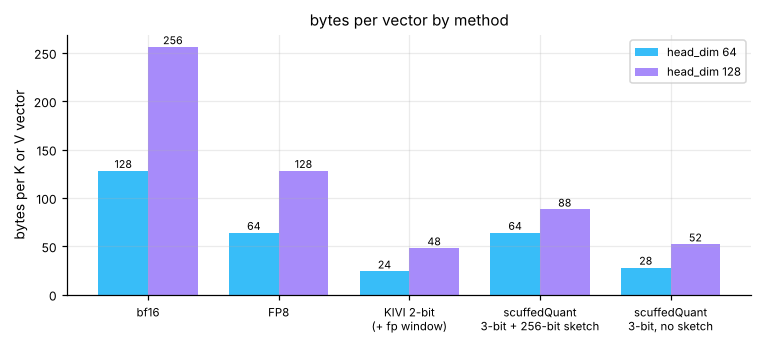

In [5]:
rows = []
N = 1024
for dd in (64, 128):
    x = rng.standard_normal((N, dd)).astype(np.float32)
    for bits in (2, 3, 4):
        for qjl in (64, 256):
            s_ = ScuffedQuant(dim=dd, bits=bits, qjl_dim=qjl, seed=42)
            c = s_.compress(x)
            wire = c.pack()
            assert len(wire) == c.nbytes
            per_vec = (len(wire) - 20) / N
            rows.append({"head_dim": dd, "bits": bits, "qjl_dim": qjl, "bytes_per_vector": per_vec,
                         "ratio_vs_fp16": dd * 2 / per_vec, "ratio_vs_fp32": dd * 4 / per_vec,
                         "unpacked_bytes_per_vector": (c.unpacked_nbytes) / N})
print(f"{'dim':>4} {'bits':>4} {'qjl':>4} {'B/vec':>7} {'vs fp16':>8} {'vs fp32':>8} {'unpacked B/vec':>15}")
for r in rows:
    print(f"{r['head_dim']:>4} {r['bits']:>4} {r['qjl_dim']:>4} {r['bytes_per_vector']:>7.1f} "
          f"{r['ratio_vs_fp16']:>8.2f} {r['ratio_vs_fp32']:>8.2f} {r['unpacked_bytes_per_vector']:>15.1f}")
# bytes per vector against the other KV compression methods (arithmetic; KIVI assumes 16-bit scale + zero per group of 32)
figb, ax = plt.subplots(figsize=(7, 3.2))
methods = ["bf16", "FP8", "KIVI 2-bit\n(+ fp window)", "scuffedQuant\n3-bit + 256-bit sketch", "scuffedQuant\n3-bit, no sketch"]
vals = {64: [128, 64, 64 * 3 / 8, 4 + 4 + 24 + 32, 4 + 24], 128: [256, 128, 128 * 3 / 8, 4 + 4 + 48 + 32, 4 + 48]}
xs = np.arange(len(methods)); w = 0.38
ax.bar(xs - w / 2, vals[64], w, color=C["cold"], label="head_dim 64"); ax.bar(xs + w / 2, vals[128], w, color=C["spill"], label="head_dim 128")
for i in range(len(methods)):
    ax.text(xs[i] - w / 2, vals[64][i] + 3, f"{vals[64][i]:.0f}", ha="center", fontsize=7); ax.text(xs[i] + w / 2, vals[128][i] + 3, f"{vals[128][i]:.0f}", ha="center", fontsize=7)
ax.set_xticks(xs); ax.set_xticklabels(methods, fontsize=7.5); ax.set_ylabel("bytes per K or V vector"); ax.legend(); ax.set_title("bytes per vector by method")
fig("11_bytes_per_vector", model=True, caption="arithmetic; FP8/KIVI change the GPU cache, scuffedQuant only the transfer")

### 3. Round trip

In [6]:
sq = ScuffedQuant(dim=64, bits=BITS, qjl_dim=QJL_DIM, seed=42)
x = rng.standard_normal((257, 64)).astype(np.float32)
c = sq.compress(x)
c2 = CompressedKV.unpack(c.pack())
q = rng.standard_normal((4, 64)).astype(np.float32)
ok = (np.array_equal(c.indices, c2.indices) and np.array_equal(c.qjl_signs, c2.qjl_signs)
      and np.array_equal(sq.attention_scores(q, c), sq.attention_scores(q, c2)))
print("round trip exact:", ok, "| wire bytes:", len(c.pack()), "| unpacked bytes:", c.unpacked_nbytes)
assert ok

round trip exact: True | wire bytes: 16468 | unpacked bytes: 84296


### 4. The sketch: error vs sketch size, with and without the correction (model figure)

Proposition 4.3 says the inner-product error with the sketch falls like $1/\sqrt m$; the reconstruction-only error (what the vLLM connector path uses today) does not depend on $m$.

figure -> docs/figures/11_sketch_error.png  |  Proposition 4.3; the reconstruction-only line is what the connector path sees


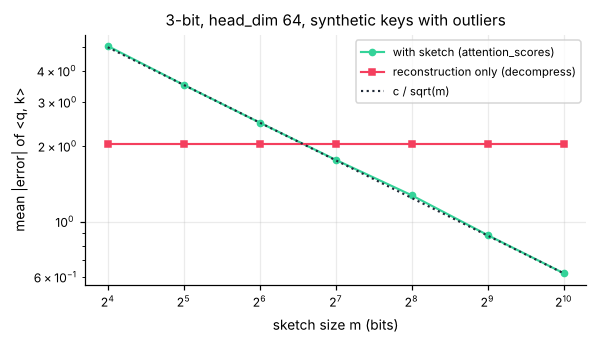

{16: (5.027, 2.044), 32: (3.516, 2.044), 64: (2.485, 2.044), 128: (1.765, 2.044), 256: (1.273, 2.044), 512: (0.883, 2.044), 1024: (0.622, 2.044)}
at m=256 the sketch cuts the error by 1.61x on these synthetic keys (2.3x on the Granite run below); below m=128 bits the sketch's own noise exceeds the quantization error and it hurts


In [7]:
ms = [16, 32, 64, 128, 256, 512, 1024]
K = X[:512]; qs = rng.standard_normal((64, d)).astype(np.float32)
exact = qs @ K.T
err_sk, err_rec = [], []
for m in ms:
    s_ = ScuffedQuant(dim=d, bits=BITS, qjl_dim=m, seed=42)
    cK = s_.compress(K)
    err_sk.append(np.abs(exact - s_.attention_scores(qs, cK)).mean())
    err_rec.append(np.abs(exact - qs @ s_.decompress(cK).T).mean())
figs, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(ms, err_sk, marker="o", color=C["ok"], label="with sketch (attention_scores)")
ax.plot(ms, err_rec, marker="s", color=C["bad"], label="reconstruction only (decompress)")
ax.plot(ms, err_sk[2] * np.sqrt(ms[2] / np.array(ms)), ls=":", color=C["ink"], label="c / sqrt(m)")
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("sketch size m (bits)"); ax.set_ylabel("mean |error| of <q, k>"); ax.legend()
ax.set_title(f"{BITS}-bit, head_dim {d}, synthetic keys with outliers")
fig("11_sketch_error", model=True, caption="Proposition 4.3; the reconstruction-only line is what the connector path sees")
print({m: (round(float(a), 3), round(float(b), 3)) for m, a, b in zip(ms, err_sk, err_rec)})
i256 = ms.index(256)
print(f"at m=256 the sketch cuts the error by {err_rec[i256] / err_sk[i256]:.2f}x on these synthetic keys (2.3x on the Granite run below);"
      f" below m={next((m for m, a, b in zip(ms, err_sk, err_rec) if a < b), None)} bits the sketch's own noise exceeds the quantization error and it hurts")

### 5. Top-8 attention overlap per layer

source: synthetic
top-8 overlap: 96.5% ± 2.6% over 8 layers (min 92.2%), QJL lowers abs error: True


figure -> docs/figures/local/11_topk_overlap.png  |  synthetic KV in local mode; the real model's KV in cluster mode


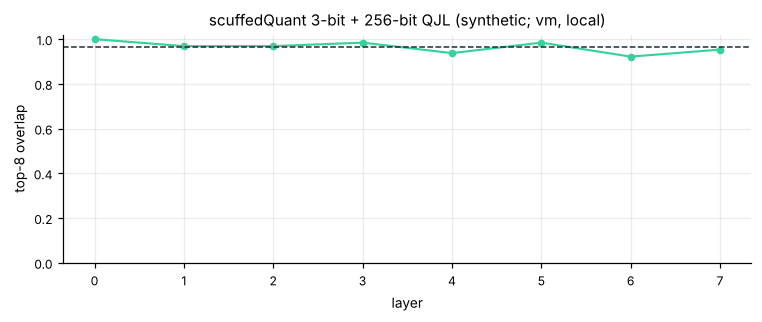

In [8]:
def topk_overlap_per_layer(layers, sq, topk=TOPK):
    out = []
    for K in layers:                      # K: (heads, seq, head_dim)
        ov, e_q, e_n = [], [], []
        for h in range(K.shape[0]):
            keys = K[h]
            query = keys[-1:, :]
            comp = sq.compress(keys)
            exact = (query @ keys.T).squeeze()
            with_qjl = sq.attention_scores(query, comp).squeeze()
            naive = (query @ sq.decompress(comp).T).squeeze()
            k = min(topk, keys.shape[0])
            ov.append(len(set(np.argsort(-exact)[:k]) & set(np.argsort(-with_qjl)[:k])) / k)
            e_q.append(np.abs(exact - with_qjl).mean()); e_n.append(np.abs(exact - naive).mean())
        out.append({"topk_overlap": float(np.mean(ov)), "abs_err_qjl": float(np.mean(e_q)), "abs_err_naive": float(np.mean(e_n))})
    return out

def summarize(per_layer):
    v = np.array([l["topk_overlap"] for l in per_layer])
    return {"layers": len(v), "mean": float(v.mean()), "std": float(v.std(ddof=1)) if len(v) > 1 else 0.0,
            "min": float(v.min()), "max": float(v.max()),
            "qjl_helps": bool(np.mean([l["abs_err_qjl"] for l in per_layer]) < np.mean([l["abs_err_naive"] for l in per_layer]))}

source = "synthetic"
layers = None
if MODE == "cluster":
    try:
        import torch
        from transformers import AutoModelForCausalLM, AutoTokenizer
        dev = DEVICE if (DEVICE == "cpu" or torch.cuda.is_available()) else "cpu"
        tok = AutoTokenizer.from_pretrained(MODEL)
        lm = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16 if dev == "cuda" else torch.float32, device_map=dev)
        prompt = ("The key-value cache in transformer inference trades memory for computation. Without it, each decode "
                  "step would recompute attention over the entire sequence, which is quadratic in sequence length. "
                  "With the cache, decode is linear: each new token only computes its own key and value projections.")
        with torch.no_grad():
            out = lm(**tok(prompt, return_tensors="pt").to(dev), use_cache=True)
        layers = [layer.keys[0].float().cpu().numpy() for layer in out.past_key_values.layers]
        source = MODEL
        del lm
    except Exception as e:
        print("model load failed, falling back to synthetic KV:", repr(e))
if layers is None:
    L, H, S, D = (8, 8, 128, 64) if MODE == "local" else (40, 8, 512, 64)
    layers = []
    for l in range(L):
        K = rng.standard_normal((H, S, D)).astype(np.float32)
        K[..., rng.choice(D, 3, replace=False)] *= 8.0      # a few outlier channels
        layers.append(K)
head_dim = layers[0].shape[-1]
sq = ScuffedQuant(dim=head_dim, bits=BITS, qjl_dim=QJL_DIM, seed=42)
per_layer = topk_overlap_per_layer(layers, sq)
summary = summarize(per_layer)
print("source:", source)
print(f"top-{TOPK} overlap: {summary['mean']*100:.1f}% ± {summary['std']*100:.1f}% over {summary['layers']} layers "
      f"(min {summary['min']*100:.1f}%), QJL lowers abs error: {summary['qjl_helps']}")
figt = plt.figure(figsize=(7, 3))
plt.plot([l["topk_overlap"] for l in per_layer], marker="o", color=C["ok"])
plt.axhline(summary["mean"], ls="--", lw=1, color=C["ink"])
plt.ylim(0, 1.02); plt.xlabel("layer"); plt.ylabel(f"top-{TOPK} overlap"); plt.title(f"scuffedQuant {BITS}-bit + {QJL_DIM}-bit QJL ({source}; {HOST}, {MODE})")
fig("11_topk_overlap", caption="synthetic KV in local mode; the real model's KV in cluster mode")

### 6. Earlier Update 4 run, re-summarized

`benchmarks/results/scuffed_quant_llm.json` (Granite 3.3-2B, 3-bit, qjl_dim 256), reported as mean ± std per layer, with the inner-product error with and without the sketch.

ibm-granite/granite-3.3-2b-instruct: top-8 91.1% ± 3.3% (min 82.8%, 40 layers), bits=3 qjl_dim=256 head_dim=64
packed bytes/vector 64: 4.00x vs FP32, 2.00x vs FP16
note: that file's kv_compressed_bytes divides FP16 bytes by the FP32 ratio, so it is 2x too small.
mean |error| of <q,k>: 25.1 with the sketch, 58.2 without


figure -> docs/figures/11_topk_granite_update4.png  |  repo results file; query = last token's key, not a real query


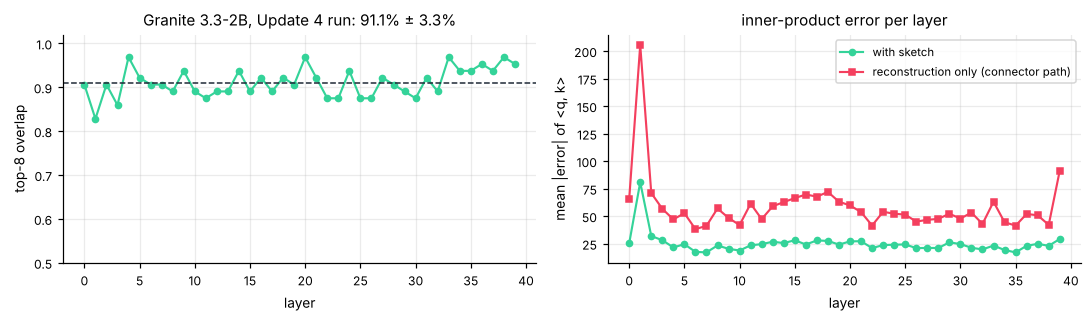

In [9]:
prev_path = ROOT / "benchmarks" / "results" / "scuffed_quant_llm.json"
prev = None
if prev_path.exists():
    prev = json.loads(prev_path.read_text())
    ps = summarize(prev["layers"])
    print(f"{prev['model']}: top-8 {ps['mean']*100:.1f}% ± {ps['std']*100:.1f}% (min {ps['min']*100:.1f}%, {ps['layers']} layers), "
          f"bits={prev['bits']} qjl_dim={prev['qjl_dim']} head_dim={prev['head_dim']}")
    hd = prev["head_dim"]
    per_vec = (hd * prev["bits"] + prev["qjl_dim"]) / 8 + 8
    print(f"packed bytes/vector {per_vec:.0f}: {hd*4/per_vec:.2f}x vs FP32, {hd*2/per_vec:.2f}x vs FP16")
    print("note: that file's kv_compressed_bytes divides FP16 bytes by the FP32 ratio, so it is 2x too small.")
    sm = prev["summary"]; print(f"mean |error| of <q,k>: {sm['mean_abs_err_qjl']:.1f} with the sketch, {sm['mean_abs_err_naive']:.1f} without")
    figg, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot([l["topk_overlap"] for l in prev["layers"]], marker="o", color=C["ok"]); ax[0].axhline(ps["mean"], ls="--", lw=1, color=C["ink"])
    ax[0].set_ylim(0.5, 1.02); ax[0].set_xlabel("layer"); ax[0].set_ylabel("top-8 overlap"); ax[0].set_title(f"Granite 3.3-2B, Update 4 run: {ps['mean']*100:.1f}% ± {ps['std']*100:.1f}%")
    ax[1].plot([l["abs_err_qjl"] for l in prev["layers"]], marker="o", color=C["ok"], label="with sketch")
    ax[1].plot([l["abs_err_naive"] for l in prev["layers"]], marker="s", color=C["bad"], label="reconstruction only (connector path)")
    ax[1].set_xlabel("layer"); ax[1].set_ylabel("mean |error| of <q, k>"); ax[1].legend(); ax[1].set_title("inner-product error per layer")
    fig("11_topk_granite_update4", model=True, caption="repo results file; query = last token's key, not a real query")
else:
    print("no earlier result file")

In [10]:
save("scuffedquant", {
    "bits": BITS, "qjl_dim": QJL_DIM, "topk": TOPK, "kv_source": source,
    "packed_sizes": rows, "per_layer": per_layer, "summary": summary,
    "sketch_error_vs_m": {str(m): {"with_sketch": float(a), "reconstruction_only": float(b)} for m, a, b in zip(ms, err_sk, err_rec)},
})

wrote /tmp/scuffed-local/scuffedquant/vm_scuffedquant.json


PosixPath('/tmp/scuffed-local/scuffedquant/vm_scuffedquant.json')